In [ ]:
import numpy as np
import pandas as pd
import joblib
import tensorflow as tf
import warnings
warnings.filterwarnings("ignore")

from google.colab import drive
drive.mount("/content/drive")

SAVE_DIR = "/content/drive/MyDrive/patient_deterioration3/"
FEATURES = ["Systolic_BP", "Respiratory_Rate",
            "Oxygen_Saturation", "Heart_Rate"]

# Load all models
ann_model = tf.keras.models.load_model(SAVE_DIR + "ann_model.keras")
svm_model = joblib.load(SAVE_DIR + "svm_model.pkl")
xgb_model = joblib.load(SAVE_DIR + "xgb_model.pkl")
rf_model  = joblib.load(SAVE_DIR + "rf_model.pkl")
lr_model  = joblib.load(SAVE_DIR + "lr_model.pkl")
scaler    = joblib.load(SAVE_DIR + "scaler.pkl")
le        = joblib.load(SAVE_DIR + "label_encoder.pkl")


print("All models loaded successfully.")

Mounted at /content/drive
All models loaded successfully.


In [ ]:
print("LabelEncoder classes:", le.classes_)
class_names = le.classes_   # ['High','Low','Medium','Normal']
risk_order  = {"High":0, "Low":1, "Medium":2, "Normal":3}
risk_labels = {0:"High", 1:"Low", 2:"Medium", 3:"Normal"}

risk_severity = {"Normal":0, "Low":1, "Medium":2, "High":3}

LabelEncoder classes: ['High' 'Low' 'Medium' 'Normal']


In [ ]:
#Generate temporal sequences and train LSTM
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from sklearn.utils.class_weight import compute_class_weight

df = pd.read_csv("Health_Risk_Dataset.csv")
df["Risk_num"] = df["Risk_Level"].map(risk_order)

noise_config = {
    "Systolic_BP"      : {"mean": -5,  "std": 3},
    "Respiratory_Rate" : {"mean": -3,  "std": 2},
    "Oxygen_Saturation": {"mean": +2,  "std": 1},
    "Heart_Rate"       : {"mean": -10, "std": 5},
}

def generate_earlier(row, hours_back):
    return np.array([
        row[f] + np.random.normal(
            noise_config[f]["mean"] * hours_back,
            noise_config[f]["std"]  * hours_back)
        for f in FEATURES
    ])

np.random.seed(42)
sequences, labels = [], []
for _, row in df.iterrows():
    t_now = row[FEATURES].values.astype(float)
    t_1hr = generate_earlier(row, 1)
    t_2hr = generate_earlier(row, 2)
    sequences.append(np.stack([t_2hr, t_1hr, t_now]))
    labels.append(row["Risk_num"])

X_seq = np.array(sequences)   # (1000, 3, 4)
y_seq = np.array(labels)

# Split and scale
idx = np.arange(len(X_seq))
tr_idx, tmp_idx = train_test_split(idx, test_size=0.30,
                                    random_state=42, stratify=y_seq)
v_idx,  te_idx  = train_test_split(tmp_idx, test_size=0.50,
                                    random_state=42, stratify=y_seq[tmp_idx])

scaler_seq = StandardScaler()
scaler_seq.fit(X_seq[tr_idx].reshape(-1, 4))

def scale_seq(X):
    return scaler_seq.transform(
        X.reshape(-1, 4)).reshape(-1, 3, 4)

X_tr = scale_seq(X_seq[tr_idx])
X_v  = scale_seq(X_seq[v_idx])
X_te = scale_seq(X_seq[te_idx])
y_tr = to_categorical(y_seq[tr_idx], 4)
y_v  = to_categorical(y_seq[v_idx],  4)

# Train LSTM
tf.random.set_seed(42)
lstm_model = Sequential([
    LSTM(64, return_sequences=True, input_shape=(3, 4)),
    Dropout(0.3),
    LSTM(32),
    Dropout(0.3),
    Dense(16, activation="relu"),
    Dropout(0.2),
    Dense(4, activation="softmax")
])
lstm_model.compile(
    optimizer=tf.keras.optimizers.Adam(0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

cw = compute_class_weight("balanced",
      classes=np.unique(y_seq[tr_idx]), y=y_seq[tr_idx])

lstm_model.fit(
    X_tr, y_tr,
    validation_data=(X_v, y_v),
    epochs=150, batch_size=32,
    class_weight=dict(enumerate(cw)),
    callbacks=[
        EarlyStopping(monitor="val_loss", patience=15,
                      restore_best_weights=True, verbose=0),
        ReduceLROnPlateau(monitor="val_loss", patience=7,
                          factor=0.5, verbose=0)
    ], verbose=1
)
print(f"LSTM Best val acc: "
      f"{max(lstm_model.history.history['val_accuracy'])*100:.2f}%")

# Save LSTM and its scaler
lstm_model.save(SAVE_DIR + "lstm_model.keras")
joblib.dump(scaler_seq, SAVE_DIR + "scaler_seq.pkl")
print("LSTM saved.")

Epoch 1/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 29ms/step - accuracy: 0.3900 - loss: 1.3712 - val_accuracy: 0.5800 - val_loss: 1.3292 - learning_rate: 0.0010
Epoch 2/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - accuracy: 0.5214 - loss: 1.2994 - val_accuracy: 0.8267 - val_loss: 1.2205 - learning_rate: 0.0010
Epoch 3/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.6329 - loss: 1.1256 - val_accuracy: 0.7467 - val_loss: 0.9552 - learning_rate: 0.0010
Epoch 4/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - accuracy: 0.6957 - loss: 0.8478 - val_accuracy: 0.8600 - val_loss: 0.6424 - learning_rate: 0.0010
Epoch 5/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7371 - loss: 0.6684 - val_accuracy: 0.8667 - val_loss: 0.4549 - learning_rate: 0.0010
Epoch 6/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7871 - loss: 0.5338 - val_accuracy: 0.8933 - val_loss: 0.3729 - learning_rate: 0.0010
Epoch 7/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.7943 - loss: 0.4923 - 

In [ ]:
# Define Agent classes + instantiate all agents
class BaseAgent:
    def __init__(self, name, model, weight, scaler, is_temporal=False):
        self.name        = name
        self.model       = model
        self.weight      = weight
        self.scaler      = scaler
        self.is_temporal = is_temporal

    def predict(self, X):
        X_scaled = self.scaler.transform(X)
        if hasattr(self.model, "predict_proba"):
            probs = self.model.predict_proba(X_scaled)
        else:
            probs = self.model.predict(X_scaled, verbose=0)
        return np.argmax(probs[0]), probs[0]

    def get_confidence(self, probs):
        return float(np.max(probs))


class TemporalAgent(BaseAgent):
    def predict(self, X_sequence):
        X_scaled = scaler_seq.transform(
            X_sequence.reshape(-1, 4)).reshape(1, 3, 4)
        probs = self.model.predict(X_scaled, verbose=0)
        return np.argmax(probs[0]), probs[0]


# Instantiate all agents with test accuracy as weight
agents = [
    BaseAgent("ANN", ann_model, weight=0.35, scaler=scaler),
    BaseAgent("SVM", svm_model, weight=0.05, scaler=scaler),
    BaseAgent("XGBoost", xgb_model, weight=0.15, scaler=scaler),
    BaseAgent("RF", rf_model, weight=0.05, scaler=scaler),
    BaseAgent("LR", lr_model, weight=0.05, scaler=scaler),
    TemporalAgent("LSTM", lstm_model,
                  weight=0.35,
                  scaler=scaler_seq,
                  is_temporal=True),
]

# Fixed class mapping — must match LabelEncoder
risk_order    = {"High":0, "Low":1, "Medium":2, "Normal":3}
risk_severity = {"Normal":0, "Low":1, "Medium":2, "High":3}
class_names   = le.classes_

print("All agents initialized:")
for a in agents:
    print(f"  {a.name:<12} weight={a.weight}  temporal={a.is_temporal}")

All agents initialized:
  ANN          weight=0.35  temporal=False
  SVM          weight=0.05  temporal=False
  XGBoost      weight=0.15  temporal=False
  RF           weight=0.05  temporal=False
  LR           weight=0.05  temporal=False
  LSTM         weight=0.35  temporal=True


In [ ]:
# MetaAgent with fixed class mapping
class MetaAgent:
    def __init__(self, agents, class_names, risk_severity):
        self.agents        = agents
        self.class_names   = class_names
        self.risk_severity = risk_severity

    def aggregate(self, X_static, X_sequence):
        agent_results = []

        for agent in self.agents:
            if agent.is_temporal:
                pred_idx, probs = agent.predict(X_sequence)
            else:
                pred_idx, probs = agent.predict(X_static)

            agent_results.append({
                "agent"     : agent.name,
                "pred_idx"  : pred_idx,
                "pred_label": self.class_names[pred_idx],
                "probs"     : probs,
                "confidence": float(np.max(probs)),
                "weight"    : agent.weight
            })

        # Weighted voting
        weighted_probs = np.zeros(len(self.class_names))
        total_weight   = sum(a["weight"] for a in agent_results)
        for a in agent_results:
            if a["agent"] == "LSTM":

                predicted_class = self.class_names[np.argmax(a["probs"])]

                if predicted_class in ["High", "Medium"]:
                   a["probs"] = a["probs"] * 1.10
            weighted_probs += (a["weight"] / total_weight) * a["probs"]

        final_idx   = np.argmax(weighted_probs)
        ann_pred = next(a["pred_idx"]
                    for a in agent_results
                    if a["agent"] == "ANN")

        lstm_pred = next(a["pred_idx"]
                    for a in agent_results
                    if a["agent"] == "LSTM")

        if ann_pred == lstm_pred:
                weighted_probs[ann_pred] *= 1.15
        final_label = self.class_names[final_idx]

        # Static majority (exclude LSTM)
        static_preds    = [a["pred_label"] for a in agent_results
                           if a["agent"] != "LSTM"]
        static_majority = max(set(static_preds),
                               key=static_preds.count)
        lstm_pred       = next(a["pred_label"] for a in agent_results
                               if a["agent"] == "LSTM")

        static_agent_probs = [
              a["probs"] for a in agent_results
              if a["agent"] != "LSTM"
        ]

        # Average probabilities of all static agents
        static_probs = np.mean(static_agent_probs, axis=0)

        # LSTM probability vector
        lstm_probs = next(
            a["probs"] for a in agent_results
            if a["agent"] == "LSTM"
        )

        # Early warning using severity scale
        static_sev    = self.risk_severity[static_majority]
        lstm_sev      = self.risk_severity[lstm_pred]
        severity_gap = lstm_sev - static_sev

        high_prob_static = weighted_probs[risk_order["High"]]
        high_prob_lstm   = lstm_probs[risk_order["High"]]

        early_warning = (
            severity_gap >= 1
            or
            (high_prob_lstm - high_prob_static > 0.20)
        )

        warning_msg = None
        if early_warning:
            warning_msg = (
                f"⚠️ EARLY WARNING: Current vitals suggest "
                f"'{static_majority}' risk but temporal trend "
                f"indicates heading towards '{lstm_pred}' risk!"
            )

        agreement = sum(
            1 for a in agent_results
            if a["pred_idx"] == final_idx) / len(agent_results)

        return {
            "final_prediction" : final_label,
            "final_idx"        : final_idx,
            "weighted_probs"   : weighted_probs,
            "agent_results"    : agent_results,
            "early_warning"    : early_warning,
            "warning_message"  : warning_msg,
            "agreement_score"  : agreement,
            "lstm_prediction"  : lstm_pred,
            "static_prediction": static_majority,
        }

meta_agent = MetaAgent(agents, class_names, risk_severity)
print("Meta Agent ready.")

Meta Agent ready.


In [ ]:
# Clinical Rule Agent
# Based on NEWS2 (National Early Warning Score 2) clinical guidelines

class ClinicalRuleAgent:
    """
    Checks patient vitals against established clinical thresholds.
    Based on NEWS2 scoring system used in hospitals.
    """
    def __init__(self):
        self.name = "ClinicalRuleAgent"

    def score_vital(self, feature, value):
        """Returns NEWS2 score for each vital sign"""
        scores = {
            "Respiratory_Rate": [
                (value <= 8,   3),
                (9  <= value <= 11, 1),
                (12 <= value <= 20, 0),
                (21 <= value <= 24, 2),
                (value >= 25,  3),
            ],
            "Oxygen_Saturation": [
                (value <= 91,  3),
                (92 <= value <= 93, 2),
                (94 <= value <= 95, 1),
                (value >= 96,  0),
            ],
            "Systolic_BP": [
                (value <= 90,  3),
                (91 <= value <= 100, 2),
                (101 <= value <= 110, 1),
                (111 <= value <= 219, 0),
                (value >= 220, 3),
            ],
            "Heart_Rate": [
                (value <= 40,  3),
                (41 <= value <= 50, 1),
                (51 <= value <= 90, 0),
                (91 <= value <= 110, 1),
                (111 <= value <= 130, 2),
                (value >= 131, 3),
            ],
        }
        for condition, score in scores.get(feature, []):
            if condition:
                return score
        return 0

    def assess(self, patient_values):
        """
        Returns NEWS2 total score and corresponding risk level
        """
        features = ["Systolic_BP", "Respiratory_Rate",
                    "Oxygen_Saturation", "Heart_Rate"]
        scores   = {}
        total    = 0

        for feat, val in zip(features, patient_values):
            s = self.score_vital(feat, val)
            scores[feat] = s
            total += s

        # NEWS2 risk mapping
        if total <= 4:
            risk = "Low"
            action = "Routine monitoring"
        elif total <= 6:
            risk = "Medium"
            action = "Urgent review by nurse/doctor"
        else:
            risk = "High"
            action = "Emergency — immediate medical review"

        if total == 0:
            risk   = "Normal"
            action = "Continue routine care"

        return {
            "agent"         : self.name,
            "news2_score"   : total,
            "feature_scores": scores,
            "risk_level"    : risk,
            "action"        : action,
            "message"       : f"NEWS2 Score: {total} → {risk} Risk — {action}"
        }

clinical_agent = ClinicalRuleAgent()
print("Clinical Rule Agent ready.")

Clinical Rule Agent ready.


In [ ]:
# Trend Agent
# Analyzes direction and velocity of vital sign changes over time

class TrendAgent:
    """
    Analyzes temporal trends from 3 hourly readings.
    Detects deteriorating patterns before crisis occurs.
    """
    def __init__(self):
        self.name = "TrendAgent"
        # For each feature: positive change = increasing risk (True)
        #                   negative change = increasing risk (False)
        self.risk_direction = {
            "Systolic_BP"      : "high",   # high BP = risk
            "Respiratory_Rate" : "high",   # high RR = risk
            "Oxygen_Saturation": "low",    # low O2  = risk
            "Heart_Rate"       : "high",   # high HR = risk
        }
        self.features = ["Systolic_BP", "Respiratory_Rate",
                         "Oxygen_Saturation", "Heart_Rate"]

    def analyze(self, reading_2hr, reading_1hr, reading_now):
        """
        Computes trend direction, velocity and acceleration
        for each vital sign
        """
        readings = np.array([reading_2hr, reading_1hr, reading_now])
        trends   = {}
        deteriorating_count = 0

        for i, feat in enumerate(self.features):
            vals = readings[:, i]

            # Rate of change (velocity)
            delta_1 = vals[1] - vals[0]   # T-2hr to T-1hr
            delta_2 = vals[2] - vals[1]   # T-1hr to T-now

            # Acceleration (is it speeding up?)
            acceleration = delta_2 - delta_1

            # Direction
            if abs(delta_2) < 0.5:
                direction = "stable"
            elif delta_2 > 0:
                direction = "increasing"
            else:
                direction = "decreasing"

            # Is this trend worsening?
            risk_dir = self.risk_direction[feat]
            if risk_dir == "high":
                worsening = delta_2 > 2    # rising = bad
            else:
                worsening = delta_2 < -2   # falling = bad

            if worsening:
                deteriorating_count += 1

            trends[feat] = {
                "values"      : vals.tolist(),
                "delta"       : round(float(delta_2), 2),
                "acceleration": round(float(acceleration), 2),
                "direction"   : direction,
                "worsening"   : worsening
            }

        # Overall trend assessment
        if deteriorating_count >= 3:
            trend_risk   = "High"
            trend_status = "RAPIDLY DETERIORATING"
        elif deteriorating_count == 2:
            trend_risk   = "Medium"
            trend_status = "DETERIORATING"
        elif deteriorating_count == 1:
            trend_risk   = "Low"
            trend_status = "MILD DETERIORATION"
        else:
            trend_risk   = "Normal"
            trend_status = "STABLE"

        return {
            "agent"               : self.name,
            "feature_trends"      : trends,
            "deteriorating_count" : deteriorating_count,
            "trend_risk"          : trend_risk,
            "trend_status"        : trend_status,
            "early_warning"       : deteriorating_count >= 2
        }

trend_agent = TrendAgent()
print("Trend Agent ready.")

Trend Agent ready.


In [ ]:
# Confidence Agent
# Evaluates reliability of each model's prediction

class ConfidenceAgent:
    """
    Assesses how confident and consistent all model agents are.
    Flags low-confidence or disagreeing predictions.
    """
    def __init__(self):
        self.name = "ConfidenceAgent"

    def evaluate(self, agent_results):
        """
        agent_results: list of dicts from model agents
        """
        confidences  = [a["confidence"] for a in agent_results]
        predictions  = [a["pred_label"] for a in agent_results]
        pred_set     = set(predictions)

        avg_confidence = np.mean(confidences)
        min_confidence = np.min(confidences)
        max_confidence = np.max(confidences)
        disagreement   = len(pred_set)       # how many unique predictions

        # Identify outlier agents (disagree with majority)
        majority_pred = max(set(predictions), key=predictions.count)
        outliers = [a["agent"] for a in agent_results
                    if a["pred_label"] != majority_pred]

        # Confidence level
        if avg_confidence >= 0.80 and disagreement <= 2:
            confidence_level = "HIGH"
            reliable         = True
        elif avg_confidence >= 0.60 and disagreement <= 3:
            confidence_level = "MEDIUM"
            reliable         = True
        else:
            confidence_level = "LOW"
            reliable         = False

        return {
            "agent"            : self.name,
            "avg_confidence"   : round(avg_confidence, 4),
            "min_confidence"   : round(min_confidence, 4),
            "max_confidence"   : round(max_confidence, 4),
            "unique_predictions": disagreement,
            "majority_pred"    : majority_pred,
            "outlier_agents"   : outliers,
            "confidence_level" : confidence_level,
            "reliable"         : reliable,
            "message"          : (
                f"Confidence: {confidence_level} "
                f"(avg={avg_confidence*100:.1f}%) — "
                f"{'Reliable' if reliable else 'Uncertain — review manually'}"
            )
        }

confidence_agent = ConfidenceAgent()
print("Confidence Agent ready.")

Confidence Agent ready.


In [ ]:
# SHAP explainer for ANN (needed by SHAPAgent)
import shap
import warnings
warnings.filterwarnings("ignore")

# ✅ Load X_train correctly using np.load (not joblib)
X_train = np.load(SAVE_DIR + "X_train.npy")

background = X_train[:100]
explainer  = shap.DeepExplainer(ann_model, background)

# Test it works
shap_values_test = explainer.shap_values(
    scaler.transform(np.array([X_seq[te_idx[0]][2]])))

if isinstance(shap_values_test, np.ndarray) and shap_values_test.ndim == 3:
    shap_values_test = [shap_values_test[:,:,i]
                        for i in range(shap_values_test.shape[2])]

print("SHAP explainer ready for SHAPAgent.")

SHAP explainer ready for SHAPAgent.


In [ ]:
# SHAP Agent
# Generates feature-level explanation for the final prediction

class SHAPAgent:
    """
    Explains the final prediction using SHAP values.
    Identifies which vital sign contributed most to the risk.
    """
    def __init__(self, model, scaler, explainer, class_names):
        self.name        = "SHAPAgent"
        self.model       = model
        self.scaler      = scaler
        self.explainer   = explainer
        self.class_names = class_names
        self.features    = ["Systolic_BP", "Respiratory_Rate",
                            "Oxygen_Saturation", "Heart_Rate"]

    def explain(self, patient_values, pred_class_idx):
        """Returns SHAP values and top contributing feature"""
        scaled = self.scaler.transform(
            np.array([patient_values]))

        sv = self.explainer.shap_values(scaled)
        if isinstance(sv, np.ndarray) and sv.ndim == 3:
            sv = [sv[:, :, i] for i in range(sv.shape[2])]

        shap_vals = sv[pred_class_idx][0]
        pred_name = self.class_names[pred_class_idx]

        # Rank features by absolute SHAP value
        ranked = sorted(
            zip(self.features, shap_vals),
            key=lambda x: abs(x[1]), reverse=True
        )

        # Build explanation text
        top_feat, top_val = ranked[0]
        direction = "increases" if top_val > 0 else "decreases"
        explanation = (
            f"Primary driver: {top_feat} "
            f"({direction} {pred_name} risk by {abs(top_val):.3f})"
        )

        return {
            "agent"         : self.name,
            "shap_values"   : dict(zip(self.features, shap_vals)),
            "ranked_features": ranked,
            "top_feature"   : top_feat,
            "top_shap_value": float(top_val),
            "explanation"   : explanation,
            "pred_class"    : pred_name
        }

shap_agent = SHAPAgent(ann_model, scaler, explainer, class_names)
print("SHAP Agent ready.")

SHAP Agent ready.


In [ ]:
# Counterfactual Agent
# Generates actionable recommendations to reduce risk

class CounterfactualAgent:
    """
    Generates minimum vital sign changes needed
    to move patient to Normal risk.
    """
    def __init__(self, model, scaler, class_names, risk_order):
        self.name        = "CounterfactualAgent"
        self.model       = model
        self.scaler      = scaler
        self.class_names = class_names
        self.risk_order  = risk_order  # {High:0,Low:1,Medium:2,Normal:3}
        self.features    = ["Systolic_BP", "Respiratory_Rate",
                            "Oxygen_Saturation", "Heart_Rate"]
        self.bounds = {
            "Systolic_BP"      : (60,  180),
            "Respiratory_Rate" : (10,  40),
            "Oxygen_Saturation": (85,  100),
            "Heart_Rate"       : (50,  180),
        }

    def generate(self, patient_values, pred_class, n=30000):
        """Generate counterfactuals toward Normal risk"""
        normal_idx = self.risk_order["Normal"]   # 3

        if pred_class == "Normal":
            return {
                "agent"  : self.name,
                "needed" : False,
                "message": "Patient already at Normal risk.",
                "suggestions": []
            }

        # Medically constrained sampling
        constrained_bounds = {
            "Systolic_BP"      : (self.bounds["Systolic_BP"][0],
                                  patient_values[0]),
            "Respiratory_Rate" : (self.bounds["Respiratory_Rate"][0],
                                  patient_values[1]),
            "Oxygen_Saturation": (patient_values[2],
                                  self.bounds["Oxygen_Saturation"][1]),
            "Heart_Rate"       : (self.bounds["Heart_Rate"][0],
                                  patient_values[3]),
        }

        samples = np.column_stack([
            np.random.uniform(
                constrained_bounds[f][0],
                constrained_bounds[f][1], n)
            for f in self.features
        ])

        preds = np.argmax(
            self.model.predict(
                self.scaler.transform(samples), verbose=0),
            axis=1)

        cf_samples = samples[preds == normal_idx]

        if len(cf_samples) == 0:
            return {
                "agent"      : self.name,
                "needed"     : True,
                "message"    : "Could not find counterfactuals.",
                "suggestions": []
            }

        # Top 3 closest
        distances = np.sum(
            np.abs(cf_samples - np.array(patient_values)), axis=1)
        top3 = cf_samples[np.argsort(distances)[:3]]

        suggestions = []
        for i, cf in enumerate(top3):
            changes = {}
            for j, feat in enumerate(self.features):
                diff   = cf[j] - patient_values[j]
                arrow  = "↑" if diff > 0 else "↓"
                changes[feat] = {
                    "original"  : round(patient_values[j], 1),
                    "suggested" : round(cf[j], 1),
                    "change"    : round(diff, 1),
                    "direction" : arrow
                }
            suggestions.append(changes)

        return {
            "agent"      : self.name,
            "needed"     : True,
            "message"    : f"Found {len(suggestions)} suggestions to reach Normal risk",
            "suggestions": suggestions
        }

cf_agent = CounterfactualAgent(
    ann_model, scaler, class_names, risk_order)
print("Counterfactual Agent ready.")

Counterfactual Agent ready.


In [ ]:
# Alert Agent
# Combines all agent outputs into a final clinical alert

class AlertAgent:
    """
    Final decision agent.
    Synthesizes all agent outputs into a
    unified clinical alert and recommendation.
    """
    def __init__(self):
        self.name = "AlertAgent"

    def generate_alert(self, meta_result, clinical_result,
                       trend_result, confidence_result,
                       shap_result, cf_result):

        final_risk    = meta_result["final_prediction"]
        news2_score   = clinical_result["news2_score"]
        trend_status  = trend_result["trend_status"]
        early_warning = (meta_result["early_warning"] or
                         trend_result["early_warning"])
        confidence    = confidence_result["confidence_level"]

        # Alert level decision
        if final_risk == "High" or news2_score >= 7:
            alert_level = "🚨 CRITICAL ALERT"
            alert_color = "RED"
            action      = "Immediate emergency intervention required"
        elif final_risk == "Medium" or news2_score >= 5:
            alert_level = "⚠️ WARNING"
            alert_color = "ORANGE"
            action      = "Urgent clinical review within 30 minutes"
        elif final_risk == "Low" or news2_score >= 1:
            alert_level = "🔵 CAUTION"
            alert_color = "YELLOW"
            action      = "Increase monitoring frequency"
        else:
            alert_level = "✅ NORMAL"
            alert_color = "GREEN"
            action      = "Continue routine care"

        # Early warning upgrade
        if early_warning and final_risk != "High":
            alert_level = "⚠️ EARLY WARNING — " + alert_level
            action      = "Trending toward higher risk — " + action

        return {
            "agent"         : self.name,
            "alert_level"   : alert_level,
            "alert_color"   : alert_color,
            "final_risk"    : final_risk,
            "news2_score"   : news2_score,
            "trend_status"  : trend_status,
            "early_warning" : early_warning,
            "action"        : action,
            "confidence"    : confidence,
            "top_driver"    : shap_result["top_feature"],
            "cf_available"  : cf_result["needed"],
        }

alert_agent = AlertAgent()
print("Alert Agent ready.")

Alert Agent ready.


In [ ]:
# CELL 7 — Complete Multi-Agent Pipeline
def full_multi_agent_pipeline(reading_2hr, reading_1hr, reading_now):
    """
    Runs all agents in sequence and produces
    final clinical decision with full explanation.
    """
    print("\n" + "="*60)
    print("   MULTI-AGENT MULTI-MODEL EARLY PREDICTION FRAMEWORK")
    print("="*60)
    print(f"\n  📋 Patient Readings:")
    print(f"     T-2hr : {reading_2hr}")
    print(f"     T-1hr : {reading_1hr}")
    print(f"     T-now : {reading_now}")

    # ── Layer 1: Specialist Agents ───────────────────────────
    print("\n  [Layer 1] Specialist Agents Running...")

    clinical_result = clinical_agent.assess(reading_now)
    print(f"  ✅ Clinical Rule Agent — {clinical_result['message']}")

    trend_result = trend_agent.analyze(
        reading_2hr, reading_1hr, reading_now)
    print(f"  ✅ Trend Agent — Status: {trend_result['trend_status']} "
          f"({trend_result['deteriorating_count']}/4 vitals deteriorating)")

    # ── Layer 2: Model Agents ────────────────────────────────
    print("\n  [Layer 2] Model Agents Running...")
    X_static   = np.array([reading_now])
    X_sequence = np.stack([reading_2hr, reading_1hr, reading_now])
    meta_result = meta_agent.aggregate(X_static, X_sequence)

    print(f"  {'Agent':<12} {'Prediction':<12} {'Confidence':>10}")
    print(f"  {'─'*38}")
    for a in meta_result["agent_results"]:
        tag = " ← temporal" if a["agent"] == "LSTM" else ""
        print(f"  {a['agent']:<12} {a['pred_label']:<12} "
              f"{a['confidence']*100:>9.1f}%{tag}")

    # ── Layer 3: Confidence Agent ────────────────────────────
    print("\n  [Layer 3] Confidence Agent Running...")
    confidence_result = confidence_agent.evaluate(
        meta_result["agent_results"])
    print(f"  ✅ {confidence_result['message']}")
    if confidence_result["outlier_agents"]:
        print(f"  ⚠️  Outlier agents: "
              f"{confidence_result['outlier_agents']}")

    # ── Layer 4: SHAP Agent ──────────────────────────────────
    print("\n  [Layer 4] SHAP Agent Running...")
    shap_result = shap_agent.explain(
        reading_now, meta_result["final_idx"])
    print(f"  ✅ {shap_result['explanation']}")
    print(f"  Feature contributions:")
    for feat, val in shap_result["ranked_features"]:
        arrow = "↑" if val > 0 else "↓"
        bar   = "█" * int(abs(val) * 50)
        print(f"     {feat:<25} {arrow} {abs(val):.3f}  {bar}")

    # ── Layer 5: Counterfactual Agent ────────────────────────
    print("\n  [Layer 5] Counterfactual Agent Running...")
    cf_result = cf_agent.generate(
        reading_now, meta_result["final_prediction"])
    print(f"  ✅ {cf_result['message']}")
    if cf_result["needed"] and cf_result["suggestions"]:
        print(f"\n  💊 Suggested changes to reach Normal risk:")
        features = ["Systolic_BP","Respiratory_Rate",
                    "Oxygen_Saturation","Heart_Rate"]
        print(f"  {'Feature':<25} {'Original':>10} "
              f"{'Suggested':>10} {'Change':>8}")
        print(f"  {'─'*55}")
        for feat in features:
            s = cf_result["suggestions"][0][feat]
            print(f"  {feat:<25} {s['original']:>10.1f} "
                  f"{s['suggested']:>10.1f} "
                  f"{s['direction']}{abs(s['change']):>6.1f}")

    # ── Layer 6: Alert Agent ─────────────────────────────────
    print("\n  [Layer 6] Alert Agent Running...")
    alert_result = alert_agent.generate_alert(
        meta_result, clinical_result, trend_result,
        confidence_result, shap_result, cf_result)

    print("\n" + "="*60)
    print(f"  {alert_result['alert_level']}")
    print(f"  Final Risk      : {alert_result['final_risk']}")
    print(f"  NEWS2 Score     : {alert_result['news2_score']}")
    print(f"  Trend Status    : {alert_result['trend_status']}")
    print(f"  Early Warning   : "
          f"{'YES ⚠️' if alert_result['early_warning'] else 'No ✅'}")
    print(f"  Confidence      : {alert_result['confidence']}")
    print(f"  Primary Driver  : {alert_result['top_driver']}")
    print(f"\n  🏥 Recommended Action: {alert_result['action']}")
    print("="*60)

    return {
        "meta"        : meta_result,
        "clinical"    : clinical_result,
        "trend"       : trend_result,
        "confidence"  : confidence_result,
        "shap"        : shap_result,
        "counterfactual": cf_result,
        "alert"       : alert_result
    }




In [ ]:
# ── Test with a deteriorating patient ───────────────────────
result = full_multi_agent_pipeline(
    reading_2hr = [115, 19, 95, 88],
    reading_1hr = [118, 22, 93, 105],
    reading_now = [120, 26, 90, 140]
)


   MULTI-AGENT MULTI-MODEL EARLY PREDICTION FRAMEWORK

  📋 Patient Readings:
     T-2hr : [115, 19, 95, 88]
     T-1hr : [118, 22, 93, 105]
     T-now : [120, 26, 90, 140]

  [Layer 1] Specialist Agents Running...
  ✅ Clinical Rule Agent — NEWS2 Score: 9 → High Risk — Emergency — immediate medical review
  ✅ Trend Agent — Status: RAPIDLY DETERIORATING (3/4 vitals deteriorating)

  [Layer 2] Model Agents Running...
  Agent        Prediction   Confidence
  ──────────────────────────────────────
  ANN          High              85.9%
  SVM          High              91.6%
  XGBoost      High              86.2%
  RF           High              81.5%
  LR           Medium            56.6%
  LSTM         Medium            99.9% ← temporal

  [Layer 3] Confidence Agent Running...
  ✅ Confidence: HIGH (avg=83.6%) — Reliable
  ⚠️  Outlier agents: ['LR', 'LSTM']

  [Layer 4] SHAP Agent Running...
  ✅ Primary driver: Heart_Rate (increases High risk by 0.480)
  Feature contributions:
     Heart_R

In [ ]:
# CELL 6 (FIXED) — Correct evaluation
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score)

y_true_list, y_pred_list, early_warn_count = [], [], 0

for i in te_idx:
    seq        = X_seq[i]                  # (3,4) unscaled
    X_static   = np.array([seq[2]])        # T-now: (1,4)
    X_sequence = seq                       # (3,4)

    # True label — use LabelEncoder mapping (High=0,Low=1,...)
    true_label = df.iloc[i]["Risk_Level"]
    true_idx   = risk_order[true_label]

    res = meta_agent.aggregate(X_static, X_sequence)

    y_true_list.append(true_idx)
    y_pred_list.append(int(res["final_idx"]))

    if res["early_warning"]:
        early_warn_count += 1

y_true_arr = np.array(y_true_list)
y_pred_arr = np.array(y_pred_list)

print("="*45)
print("  MULTI-AGENT FRAMEWORK — TEST RESULTS")
print("="*45)
print(f"  Accuracy  : {accuracy_score(y_true_arr, y_pred_arr)*100:.2f}%")
print(f"  Precision : {precision_score(y_true_arr, y_pred_arr, average='macro', zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_true_arr, y_pred_arr, average='macro', zero_division=0):.4f}")
print(f"  F1 Score  : {f1_score(y_true_arr, y_pred_arr, average='macro', zero_division=0):.4f}")
print("="*45)
print(f"\n  Early warnings triggered : {early_warn_count} / {len(te_idx)} patients")
print(f"  Early warning rate       : {early_warn_count/len(te_idx)*100:.1f}%")

  MULTI-AGENT FRAMEWORK — TEST RESULTS
  Accuracy  : 92.67%
  Precision : 0.9356
  Recall    : 0.9357
  F1 Score  : 0.9352

  Early warnings triggered : 3 / 150 patients
  Early warning rate       : 2.0%


  LSTM MODEL — TEST RESULTS
  Accuracy  : 91.33%
  Precision : 0.9180
  Recall    : 0.9237
  F1 Score  : 0.9205
  AUC       : 0.9862

Classification Report:
              precision    recall  f1-score   support

        High     0.9756    0.9524    0.9639        42
         Low     0.8500    0.8947    0.8718        38
      Medium     0.8864    0.8478    0.8667        46
      Normal     0.9600    1.0000    0.9796        24

    accuracy                         0.9133       150
   macro avg     0.9180    0.9237    0.9205       150
weighted avg     0.9139    0.9133    0.9132       150



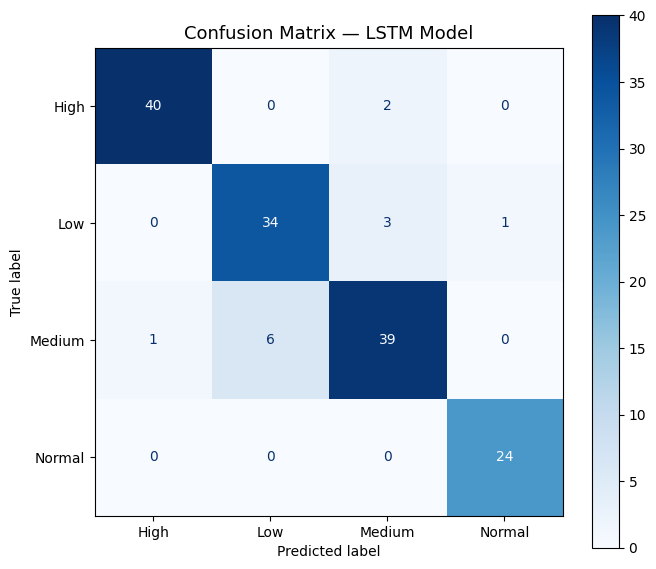

Saved: LSTM_Confusion_Matrix.png


In [ ]:
# CELL A — Evaluate LSTM model
from sklearn.metrics import (accuracy_score, precision_score,
                              recall_score, f1_score, roc_auc_score,
                              confusion_matrix, ConfusionMatrixDisplay,
                              classification_report)
from sklearn.preprocessing import label_binarize
import matplotlib.pyplot as plt

y_true_lstm = y_seq[te_idx]
y_pred_lstm_probs = lstm_model.predict(X_te, verbose=0)
y_pred_lstm = np.argmax(y_pred_lstm_probs, axis=1)
y_test_bin_lstm = label_binarize(y_true_lstm, classes=[0,1,2,3])

risk_labels_ordered = ["High", "Low", "Medium", "Normal"]

print("="*45)
print("  LSTM MODEL — TEST RESULTS")
print("="*45)
print(f"  Accuracy  : {accuracy_score(y_true_lstm, y_pred_lstm)*100:.2f}%")
print(f"  Precision : {precision_score(y_true_lstm, y_pred_lstm, average='macro', zero_division=0):.4f}")
print(f"  Recall    : {recall_score(y_true_lstm, y_pred_lstm,    average='macro', zero_division=0):.4f}")
print(f"  F1 Score  : {f1_score(y_true_lstm, y_pred_lstm,        average='macro', zero_division=0):.4f}")
print(f"  AUC       : {roc_auc_score(y_test_bin_lstm, y_pred_lstm_probs, multi_class='ovr', average='macro'):.4f}")
print("="*45)
print("\nClassification Report:")
print(classification_report(y_true_lstm, y_pred_lstm,
                             target_names=risk_labels_ordered, digits=4))

# Confusion matrix
cm   = confusion_matrix(y_true_lstm, y_pred_lstm)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                               display_labels=risk_labels_ordered)
fig, ax = plt.subplots(figsize=(7, 6))
disp.plot(ax=ax, colorbar=True, cmap="Blues")
ax.set_title("Confusion Matrix — LSTM Model", fontsize=13)
plt.tight_layout()
plt.savefig("LSTM_Confusion_Matrix.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: LSTM_Confusion_Matrix.png")

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import numpy as np
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay,
                              f1_score, accuracy_score)

# ── Collect all agent predictions on test set first ──────────
agent_names = [a.name for a in agents]
agent_preds = {name: [] for name in agent_names}
y_true_ma   = []
y_pred_ma   = []
early_warnings = []

for i in te_idx:
    seq        = X_seq[i]
    X_static   = np.array([seq[2]])
    X_sequence = seq
    true_label = df.iloc[i]["Risk_Level"]
    true_idx   = risk_order[true_label]

    res = meta_agent.aggregate(X_static, X_sequence)
    y_true_ma.append(true_idx)
    y_pred_ma.append(int(res["final_idx"]))
    early_warnings.append(res["early_warning"])

    for a in res["agent_results"]:
        agent_preds[a["agent"]].append(a["pred_idx"])

y_true_ma    = np.array(y_true_ma)
y_pred_ma    = np.array(y_pred_ma)
ew_flags     = np.array(early_warnings)
risk_labels_ordered = ["High", "Low", "Medium", "Normal"]
colors = ["#3B8BD4","#1D9E75","#EF9F27",
          "#8B5CF6","#E24B4A","#F472B6","#E85D24"]

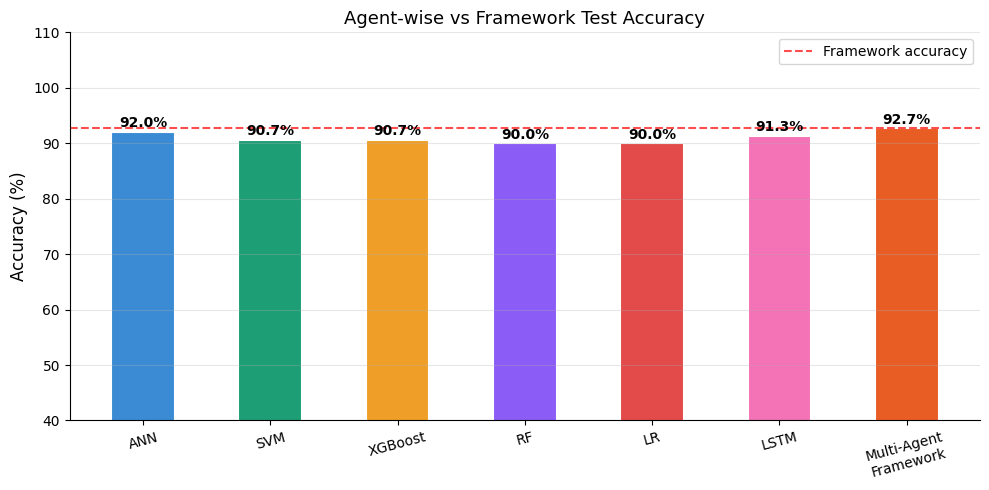

Saved: Plot1_Agent_Accuracy_Comparison.png


In [ ]:
# ── PLOT 1 — Agent accuracy comparison ──────────────────────
agent_accs = {}
for name, preds in agent_preds.items():
    agent_accs[name] = accuracy_score(
        y_true_ma, np.array(preds)) * 100
agent_accs["Multi-Agent\nFramework"] = accuracy_score(
    y_true_ma, y_pred_ma) * 100

fig1, ax1 = plt.subplots(figsize=(10, 5))
bars = ax1.bar(list(agent_accs.keys()),
               list(agent_accs.values()),
               color=colors, edgecolor="white",
               linewidth=1.5, width=0.5)
for bar, val in zip(bars, agent_accs.values()):
    ax1.text(bar.get_x() + bar.get_width()/2,
             bar.get_height() + 0.3,
             f"{val:.1f}%", ha="center", va="bottom",
             fontsize=10, fontweight="bold")
ax1.set_ylim(40, 110)
ax1.set_ylabel("Accuracy (%)", fontsize=12)
ax1.set_title("Agent-wise vs Framework Test Accuracy",
              fontsize=13)
ax1.tick_params(axis="x", rotation=15, labelsize=10)
ax1.grid(axis="y", alpha=0.3)
ax1.spines["top"].set_visible(False)
ax1.spines["right"].set_visible(False)
ax1.axhline(y=agent_accs["Multi-Agent\nFramework"],
            color="red", linestyle="--", linewidth=1.5,
            alpha=0.7, label="Framework accuracy")
ax1.legend(fontsize=10)
plt.tight_layout()
plt.savefig("Plot1_Agent_Accuracy_Comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: Plot1_Agent_Accuracy_Comparison.png")

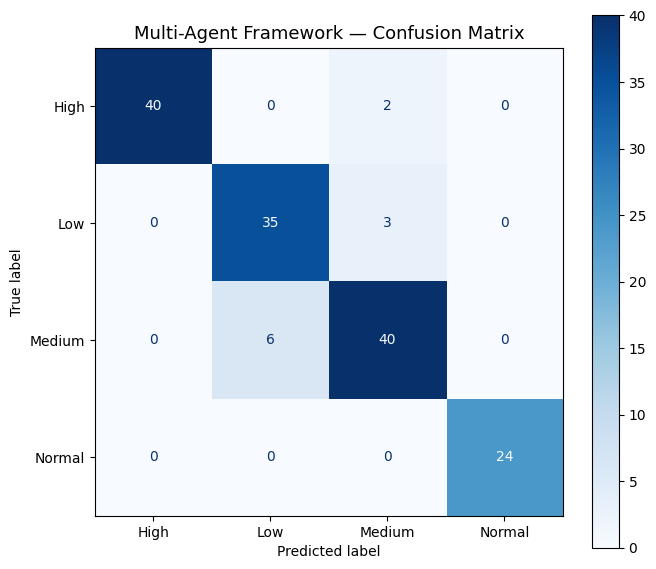

Saved: Plot2_Framework_Confusion_Matrix.png


In [ ]:
fig2, ax2 = plt.subplots(figsize=(7, 6))
cm_ma = confusion_matrix(y_true_ma, y_pred_ma)
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_ma,
    display_labels=risk_labels_ordered)
disp2.plot(ax=ax2, colorbar=True, cmap="Blues")
ax2.set_title("Multi-Agent Framework — Confusion Matrix",
              fontsize=13)
plt.tight_layout()
plt.savefig("Plot2_Framework_Confusion_Matrix.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: Plot2_Framework_Confusion_Matrix.png")


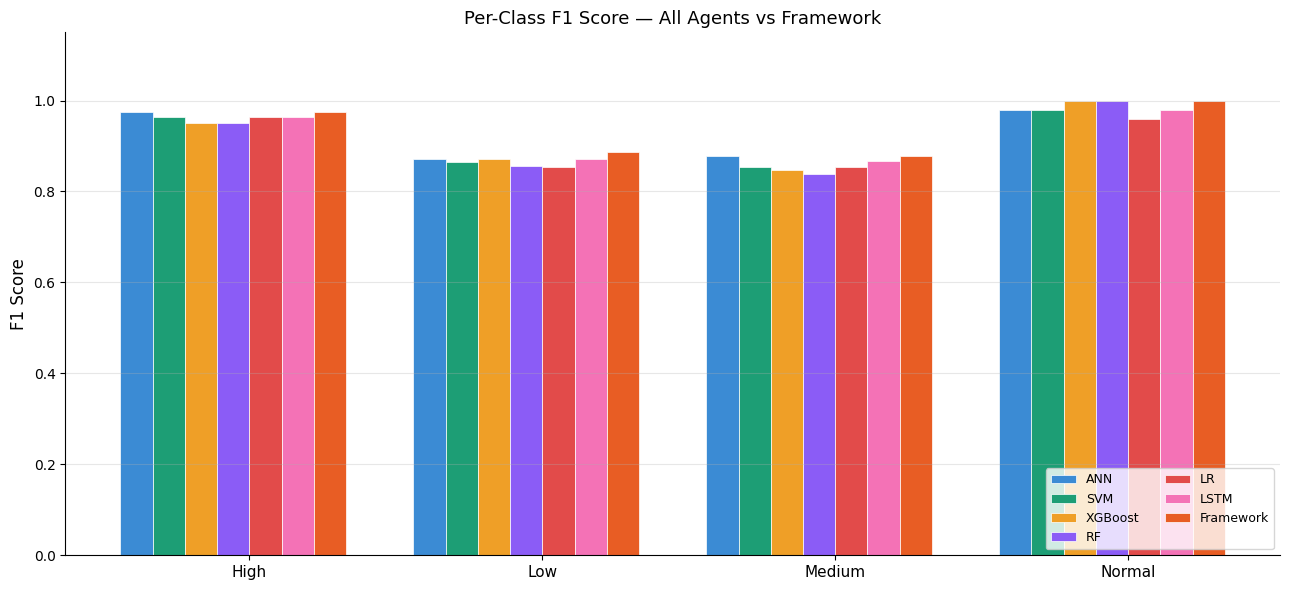

Saved: Plot3_PerClass_F1_Comparison.png


In [ ]:
agent_list = list(agent_preds.keys()) + ["Framework"]
all_preds  = list(agent_preds.values()) + [y_pred_ma.tolist()]
classes    = risk_labels_ordered
x          = np.arange(len(classes))
width      = 0.11

fig3, ax3 = plt.subplots(figsize=(13, 6))
for idx, (name, preds) in enumerate(zip(agent_list, all_preds)):
    f1s    = f1_score(y_true_ma, np.array(preds),
                      average=None, zero_division=0,
                      labels=[0,1,2,3])
    offset = (idx - len(agent_list)/2) * width
    ax3.bar(x + offset, f1s, width, label=name,
            color=colors[idx], edgecolor="white",
            linewidth=0.5)

ax3.set_xticks(x)
ax3.set_xticklabels(classes, fontsize=11)
ax3.set_ylabel("F1 Score", fontsize=12)
ax3.set_title("Per-Class F1 Score — All Agents vs Framework",
              fontsize=13)
ax3.legend(fontsize=9, loc="lower right", ncol=2)
ax3.set_ylim(0, 1.15)
ax3.grid(axis="y", alpha=0.3)
ax3.spines["top"].set_visible(False)
ax3.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("Plot3_PerClass_F1_Comparison.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: Plot3_PerClass_F1_Comparison.png")

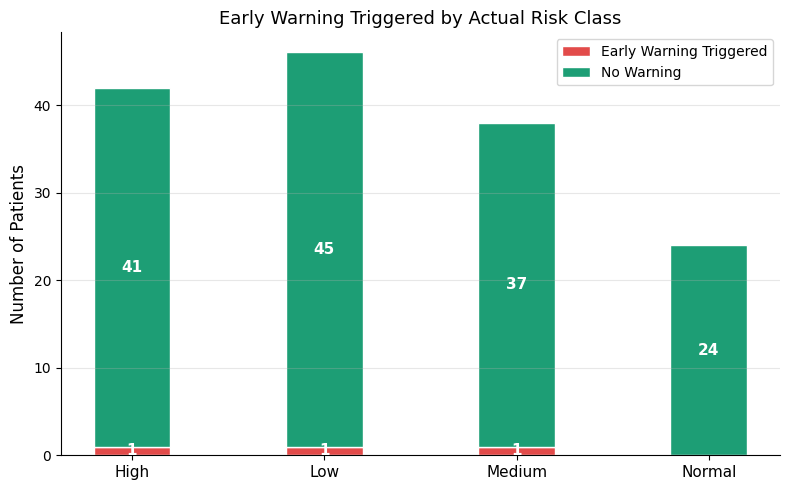

Saved: Plot4_Early_Warning_Distribution.png


In [ ]:
high_idx   = np.where(y_true_ma == risk_order["High"])[0]
medium_idx = np.where(y_true_ma == risk_order["Medium"])[0]
low_idx    = np.where(y_true_ma == risk_order["Low"])[0]
normal_idx = np.where(y_true_ma == risk_order["Normal"])[0]

ew_by_class = {
    "High"  : int(ew_flags[high_idx].sum()),
    "Medium": int(ew_flags[medium_idx].sum()),
    "Low"   : int(ew_flags[low_idx].sum()),
    "Normal": int(ew_flags[normal_idx].sum()),
}
no_ew_by_class = {
    "High"  : len(high_idx)   - ew_by_class["High"],
    "Medium": len(medium_idx) - ew_by_class["Medium"],
    "Low"   : len(low_idx)    - ew_by_class["Low"],
    "Normal": len(normal_idx) - ew_by_class["Normal"],
}

fig4, ax4 = plt.subplots(figsize=(8, 5))
x4    = np.arange(len(classes))
bars1 = ax4.bar(x4, list(ew_by_class.values()),
                color="#E24B4A", width=0.4,
                label="Early Warning Triggered",
                edgecolor="white")
bars2 = ax4.bar(x4, list(no_ew_by_class.values()),
                bottom=list(ew_by_class.values()),
                color="#1D9E75", width=0.4,
                label="No Warning", edgecolor="white")

for bar in bars1:
    if bar.get_height() > 0:
        ax4.text(bar.get_x() + bar.get_width()/2,
                 bar.get_height()/2,
                 str(int(bar.get_height())),
                 ha="center", va="center",
                 color="white", fontsize=11,
                 fontweight="bold")
for bar, base in zip(bars2, ew_by_class.values()):
    if bar.get_height() > 0:
        ax4.text(bar.get_x() + bar.get_width()/2,
                 base + bar.get_height()/2,
                 str(int(bar.get_height())),
                 ha="center", va="center",
                 color="white", fontsize=11,
                 fontweight="bold")

ax4.set_xticks(x4)
ax4.set_xticklabels(classes, fontsize=11)
ax4.set_ylabel("Number of Patients", fontsize=12)
ax4.set_title("Early Warning Triggered by Actual Risk Class",
              fontsize=13)
ax4.legend(fontsize=10)
ax4.grid(axis="y", alpha=0.3)
ax4.spines["top"].set_visible(False)
ax4.spines["right"].set_visible(False)
plt.tight_layout()
plt.savefig("Plot4_Early_Warning_Distribution.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: Plot4_Early_Warning_Distribution.png")

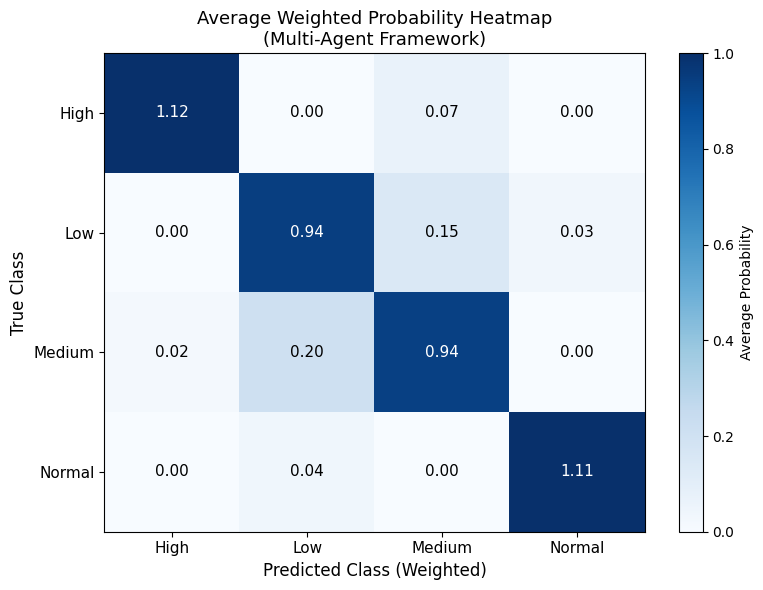

Saved: Plot5_Probability_Heatmap.png

✅ All 5 plots saved individually.


In [ ]:
prob_matrix = np.zeros((4, 4))
counts      = np.zeros(4)

for i in te_idx:
    seq      = X_seq[i]
    true_idx = risk_order[df.iloc[i]["Risk_Level"]]
    res      = meta_agent.aggregate(
        np.array([seq[2]]), seq)
    prob_matrix[true_idx] += res["weighted_probs"]
    counts[true_idx] += 1

for i in range(4):
    if counts[i] > 0:
        prob_matrix[i] /= counts[i]

fig5, ax5 = plt.subplots(figsize=(8, 6))
im = ax5.imshow(prob_matrix, cmap="Blues",
                aspect="auto", vmin=0, vmax=1)
plt.colorbar(im, ax=ax5, label="Average Probability")
ax5.set_xticks(range(4))
ax5.set_yticks(range(4))
ax5.set_xticklabels(risk_labels_ordered, fontsize=11)
ax5.set_yticklabels(risk_labels_ordered, fontsize=11)
ax5.set_xlabel("Predicted Class (Weighted)", fontsize=12)
ax5.set_ylabel("True Class", fontsize=12)
ax5.set_title("Average Weighted Probability Heatmap\n"
              "(Multi-Agent Framework)", fontsize=13)
for i in range(4):
    for j in range(4):
        ax5.text(j, i, f"{prob_matrix[i,j]:.2f}",
                 ha="center", va="center",
                 color="black" if prob_matrix[i,j] < 0.6
                 else "white", fontsize=11)
plt.tight_layout()
plt.savefig("Plot5_Probability_Heatmap.png",
            dpi=150, bbox_inches="tight")
plt.show()
plt.close()
print("Saved: Plot5_Probability_Heatmap.png")

print("\n✅ All 5 plots saved individually.")

In [ ]:
# CELL C — Save everything for Streamlit dashboard
import joblib
import os

SAVE_DIR = "/content/drive/MyDrive/patient_deterioration3/"

# ── Save LSTM model and its scaler ───────────────────────────
lstm_model.save(SAVE_DIR + "lstm_model.keras")
joblib.dump(scaler_seq, SAVE_DIR + "scaler_seq.pkl")

# ── Save agent configuration ─────────────────────────────────
agent_config = {
    "agent_names"  : [a.name for a in agents],
    "agent_weights": {a.name: a.weight for a in agents},
    "is_temporal"  : {a.name: a.is_temporal for a in agents},
    "risk_order"   : risk_order,
    "risk_severity": risk_severity,
    "class_names"  : list(class_names),
    "features"     : ["Systolic_BP", "Respiratory_Rate",
                      "Oxygen_Saturation", "Heart_Rate"]
}
joblib.dump(agent_config, SAVE_DIR + "agent_config.pkl")

# ── Save NEWS2 clinical bounds ────────────────────────────────
joblib.dump(clinical_agent,      SAVE_DIR + "clinical_agent.pkl")
joblib.dump(trend_agent,         SAVE_DIR + "trend_agent.pkl")
joblib.dump(confidence_agent,    SAVE_DIR + "confidence_agent.pkl")
joblib.dump(alert_agent,         SAVE_DIR + "alert_agent.pkl")

# ── Save X_train for SHAP background ────────────────────────
np.save(SAVE_DIR + "X_train.npy", X_train)

print("="*50)
print("  ALL FILES SAVED FOR STREAMLIT DASHBOARD")
print("="*50)
print("\nFiles saved:")
saved_files = [
    "ann_model.keras", "lstm_model.keras",
    "svm_model.pkl",   "xgb_model.pkl",
    "rf_model.pkl",    "lr_model.pkl",
    "scaler.pkl",      "scaler_seq.pkl",
    "label_encoder.pkl","agent_config.pkl",
    "clinical_agent.pkl","trend_agent.pkl",
    "confidence_agent.pkl","alert_agent.pkl",
    "X_train.npy"
]
for f in saved_files:
    path = SAVE_DIR + f
    exists = "✅" if os.path.exists(path) else "❌"
    print(f"  {exists}  {f}")

  ALL FILES SAVED FOR STREAMLIT DASHBOARD

Files saved:
  ✅  ann_model.keras
  ✅  lstm_model.keras
  ✅  svm_model.pkl
  ✅  xgb_model.pkl
  ✅  rf_model.pkl
  ✅  lr_model.pkl
  ✅  scaler.pkl
  ✅  scaler_seq.pkl
  ✅  label_encoder.pkl
  ✅  agent_config.pkl
  ✅  clinical_agent.pkl
  ✅  trend_agent.pkl
  ✅  confidence_agent.pkl
  ✅  alert_agent.pkl
  ✅  X_train.npy


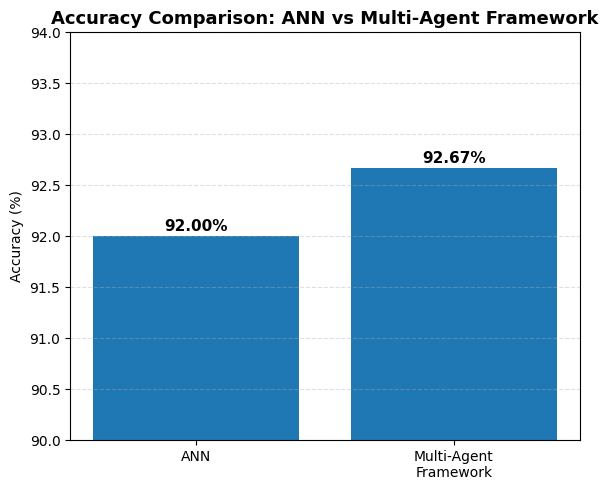

In [ ]:
import matplotlib.pyplot as plt

models = ["ANN", "Multi-Agent\nFramework"]
accuracies = [92.00, 92.67]

plt.figure(figsize=(6,5))

bars = plt.bar(models, accuracies)

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 0.05,
        f"{height:.2f}%",
        ha='center',
        fontsize=11,
        fontweight='bold'
    )

plt.title("Accuracy Comparison: ANN vs Multi-Agent Framework",
          fontsize=13,
          fontweight='bold')

plt.ylabel("Accuracy (%)")
plt.ylim(90, 94)

plt.grid(axis='y', linestyle='--', alpha=0.4)

plt.tight_layout()
plt.savefig("ANN_vs_MultiAgent_Accuracy.png", dpi=300)
plt.show()